In [2]:
import torch
from torch import nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets
from torchvision.transforms import v2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [15]:
# import data 

df = pd.read_csv("bangkok_dengue_weather_monthly.csv")

df.drop(columns=[f"valid_time_w{i}" for i in range(1, 5)], inplace=True)

# Format to datetime
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

print(df.head())
print("DataFrame shape:", df.shape)

        date  dengue_total      d2m_w1      d2m_w2      d2m_w3      d2m_w4  \
0 1993-01-01           194  292.710655  294.799441  294.909541  286.753935   
1 1993-02-01           159  287.174452  294.459790  294.526880  294.815038   
2 1993-03-01           175  296.358405  296.250377  297.016198  295.958759   
3 1993-04-01           130  297.338830  296.478047  295.737202  296.824165   
4 1993-05-01           151  297.447897  297.120339  297.430493  297.870821   

       t2m_w1      t2m_w2      t2m_w3      t2m_w4     tp_w1     tp_w2  \
0  300.161210  300.824044  300.735656  296.970963  0.000026  0.001966   
1  298.823327  300.398823  300.922179  301.672267  0.000000  0.000630   
2  302.082197  301.358856  302.137521  302.993802  0.005665  0.032537   
3  304.769734  303.957586  303.209559  304.495150  0.000615  0.013452   
4  305.519385  303.958085  301.950787  303.347884  0.004040  0.018373   

      tp_w3     tp_w4  
0  0.006118  0.002281  
1  0.002067  0.000342  
2  0.018873  0.00442

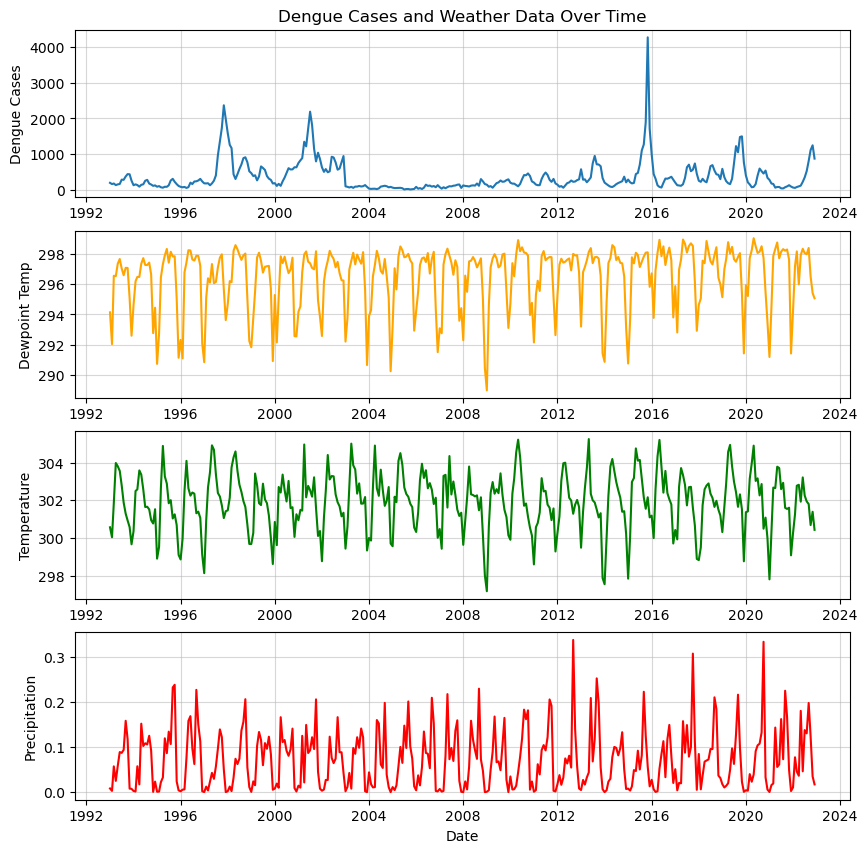

In [16]:
# Plot dengue cases over time along with weather data 
fig, ax = plt.subplots(4, 1, figsize=(10, 10))
ax[0].plot(df["date"], df["dengue_total"],
           label="Total Cases")
ax[1].plot(df["date"], 
           np.mean([df[f"d2m_w{i}"] for i in range(1, 4)], axis=0),
           color="orange",
           label="2m Dewpoint temperature")
ax[2].plot(df["date"], 
           np.mean([df[f"t2m_w{i}"] for i in range(1, 4)], axis=0),
           color="green",
           label="2m Temperature")
ax[3].plot(df["date"], 
           np.sum([df[f"tp_w{i}"] for i in range(1, 4)], axis=0),
           color="red",
           label="Total Precipitation")
ax[3].set_xlabel("Date")
ax[0].set_ylabel("Dengue Cases")
ax[1].set_ylabel("Dewpoint Temp")
ax[2].set_ylabel("Temperature")
ax[3].set_ylabel("Precipitation")
ax[0].set_title("Dengue Cases and Weather Data Over Time")
for a in ax:
    a.grid(True, alpha=0.5)
plt.show()

We will create a custom Pytorch Dataset that generates the appropriate input and target vectors.  For a window beginning at week $t$, we'll observe 24 weeks (6 months) of historical weather data and historical Dengue cases. I.e.
$$
X_t = 
\begin{bmatrix}
    W_{m-5} & D_{m-5} \\
    W_{m-4} & D_{m-4} \\
    \vdots & \vdots \\
    W_{m} & D_{m}
\end{bmatrix}
$$
where $W_t$ represents the weather variables, and $D_t$ represents the historical monthly Dengue count.  The target is 
$$
Y_t = \begin{bmatrix}
    D_{m+1} & \cdots & D_{m+6}
\end{bmatrix}
$$
where $m$ is the month containing the final week of the input window. Note that $X_t$ will be a $6\times 13$ matrix, and $Y_t$ will be in $\mathbb{R}^6$. 

In [17]:
class DengueDataset(Dataset):

    def __init__(self, X, Y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.Y = torch.tensor(Y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.Y[idx]

    def __repr__(self):
        return f"DengueDataset(X={self.X.shape}, Y={self.Y.shape})" 

In [22]:
X = []
Y = []

window_size = 6
forecast_months = 3

weather_cols = [
    col for col in df.columns
    if col not in ["dengue_total"]
]

# Monthly dengue case counts
monthly_cases = (
    df.assign(
        month=df["date"].dt.to_period("M")
    )
    .drop_duplicates("month")
    .dropna()
    .set_index("month")["dengue_total"]
    .sort_index()
)

input_cols = weather_cols + ["dengue_total"]

for i in range(len(df) - window_size + 1):

    # 6 months of historical data
    window = df.iloc[i:i+window_size].drop(columns=["date"])

    # Last month represented in the input window
    last_month = df["date"].iloc[i+window_size-1].to_period("M")

    # The following 3 calendar months
    target_periods = pd.period_range(
        start=last_month + 1,
        periods=forecast_months,
        freq="M"
    )

    # Skip samples for which all six target months aren't available
    if not target_periods.isin(monthly_cases.index).all():
        continue

    # Weather + historical cases
    x = window[input_cols].to_numpy(dtype=np.float32)

    # six monthly case counts
    y = monthly_cases.loc[target_periods].to_numpy(dtype=np.float32)

    X.append(x)
    Y.append(y)

X = np.array(X, dtype=np.float32)
Y = np.array(Y, dtype=np.float32)

print(X.shape, Y.shape)


KeyError: "['date'] not in index"

In [19]:
print(weather_cols)

['date', 'd2m_w1', 'd2m_w2', 'd2m_w3', 'd2m_w4', 't2m_w1', 't2m_w2', 't2m_w3', 't2m_w4', 'tp_w1', 'tp_w2', 'tp_w3', 'tp_w4']
